# Kathmandu Rainfall Prediction

This notebook is a presentation-friendly version of the Python project. It uses Kathmandu historical weather data and a simple `LinearRegression` model to predict the **next 3 days of total rainfall**.

Important: this is **not a direct flood prediction model** because the dataset does not contain confirmed flood-event labels or river-level values. The final result is a simple rainfall-based risk indicator.

## Module 1: Setup

We import the libraries needed for data analysis, machine learning, and graphs. The project intentionally stays simple: `pandas`, `numpy`, `matplotlib`, and `scikit-learn`.

In [ ]:
import os
from pathlib import Path

PROJECT_DIR = Path("/Users/rojanshrestha/Documents/prg330/python_with_data/presentation")
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_DIR / ".matplotlib-cache"))
Path(os.environ["MPLCONFIGDIR"]).mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

plt.style.use("seaborn-v0_8-whitegrid")


file_path = PROJECT_DIR / "Kathmandu_Daily_Climate_Data.csv"
selected_date = "2020-07-03"

if not file_path.exists():
    raise FileNotFoundError(f"CSV file not found: {file_path}")

print("Notebook setup complete")
print(f"Using CSV file: {file_path}")

Notebook setup complete
Using CSV file: /Users/rojanshrestha/Documents/prg330/python_with_data/presentation/Kathmandu_Daily_Climate_Data.csv


## Module 2: Load Data

This function loads the actual `Kathmandu_Daily_Climate_Data.csv` file, creates a real `DATE` column from `YEAR` and `DOY`, and sorts the rows by date. This makes the analysis chronological instead of random.

In [2]:
def load_data(file_path):
    df = pd.read_csv(file_path)

    required_columns = ["YEAR", "DOY", "PRECTOTCORR", "RH2M", "T2M", "PS"]
    missing_columns = [column for column in required_columns if column not in df.columns]
    if missing_columns:
        raise ValueError(f"Missing columns in dataset: {missing_columns}")

    df["DATE"] = pd.to_datetime(
        df["YEAR"].astype(int).astype(str),
        format="%Y",
    ) + pd.to_timedelta(df["DOY"].astype(int) - 1, unit="D")

    df = df.sort_values("DATE").reset_index(drop=True)
    return df


df = load_data(file_path)
required_columns = ["YEAR", "DOY", "PRECTOTCORR", "RH2M", "T2M", "PS"]

print(f"CSV file: {file_path.name}")
print(f"Dataset rows: {len(df)}")
print(f"Date range: {df['DATE'].min().date()} to {df['DATE'].max().date()}")
print(f"Selected demo date exists: {(df['DATE'] == pd.Timestamp(selected_date)).any()}")
display(df[["DATE", "PRECTOTCORR", "RH2M", "T2M", "PS"]].head())

CSV file: Kathmandu_Daily_Climate_Data.csv
Dataset rows: 15340
Date range: 1982-01-01 to 2023-12-31
Selected demo date exists: True


,DATE,PRECTOTCORR,RH2M,T2M,PS
0,1982-01-01,0.0,41.69,10.93,87.60
1,1982-01-02,0.0,41.00,10.20,87.45
2,1982-01-03,0.0,41.19,11.08,87.49
3,1982-01-04,0.0,39.25,13.26,87.71
4,1982-01-05,0.0,46.62,14.07,87.67


### Real Data Check

Before training the model, we check the actual CSV data. This confirms the number of rows, the date range, missing values, and basic rainfall statistics.

In [3]:
data_check = pd.DataFrame({
    "Metric": [
        "Rows",
        "Start date",
        "End date",
        "Average daily rainfall",
        "Maximum daily rainfall",
        "Days with zero rainfall",
        "Days with rainfall >= 22.7 mm",
    ],
    "Value": [
        len(df),
        str(df["DATE"].min().date()),
        str(df["DATE"].max().date()),
        f"{df['PRECTOTCORR'].mean():.2f} mm",
        f"{df['PRECTOTCORR'].max():.2f} mm",
        int((df["PRECTOTCORR"] == 0).sum()),
        int((df["PRECTOTCORR"] >= 22.7).sum()),
    ],
})

missing_check = df[required_columns].isna().sum().reset_index()
missing_check.columns = ["Column", "Missing values"]

print("Dataset summary")
display(data_check)
print("Missing value check")
display(missing_check)

Dataset summary


,Metric,Value
0,Rows,15340
1,Start date,1982-01-01
2,End date,2023-12-31
3,Average daily rainfall,2.50 mm
4,Maximum daily rainfall,91.66 mm
5,Days with zero rainfall,6512
6,Days with rainfall >= 22.7 mm,243


Missing value check


,Column,Missing values
0,YEAR,0
1,DOY,0
2,PRECTOTCORR,0
3,RH2M,0
4,T2M,0
5,PS,0


### Graph 1: Daily Rainfall Over Time

This graph shows how rainfall changes across the full historical dataset. Rainfall has many zero or low-rain days, with occasional heavy rainfall spikes.

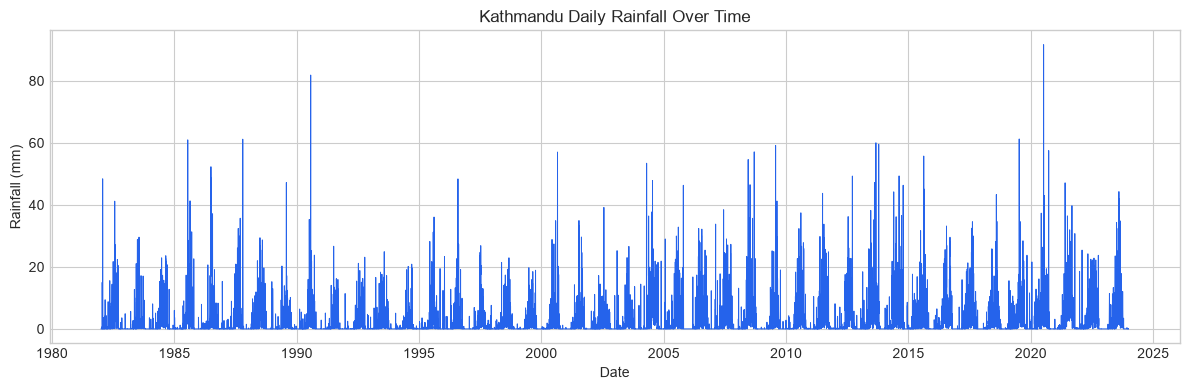

In [4]:
plt.figure(figsize=(12, 4))
plt.plot(df["DATE"], df["PRECTOTCORR"], linewidth=0.7, color="#2563eb")
plt.title("Kathmandu Daily Rainfall Over Time")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.tight_layout()
plt.show()

### Graph 2: Yearly Rainfall Total

This graph shows how much total rainfall was recorded each year in the CSV. It helps prove that the project is analyzing the real historical dataset, not a hard-coded example.

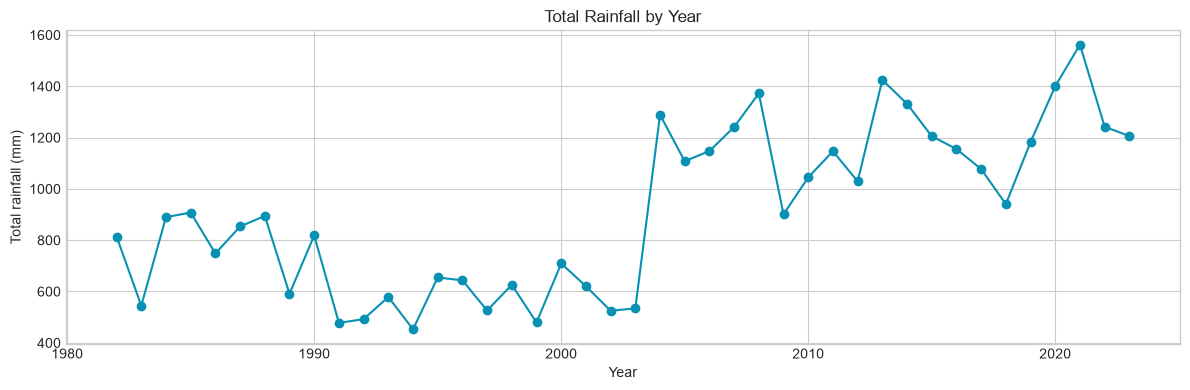

In [5]:
yearly_rain = df.assign(YEAR=df["DATE"].dt.year).groupby("YEAR")["PRECTOTCORR"].sum()

plt.figure(figsize=(12, 4))
plt.plot(yearly_rain.index, yearly_rain.values, marker="o", linewidth=1.5, color="#0891b2")
plt.title("Total Rainfall by Year")
plt.xlabel("Year")
plt.ylabel("Total rainfall (mm)")
plt.tight_layout()
plt.show()

## Module 3: Prepare Features and Target

We create rainfall features using only information available on or before the selected day. The target, `next_3d_rain`, is future rainfall and is used only as the answer during training.

In [6]:
def prepare_data(df):
    data = df.copy()

    data["rain_1d_ago"] = data["PRECTOTCORR"].shift(1)
    data["rain_2d_ago"] = data["PRECTOTCORR"].shift(2)
    data["rain_3d_ago"] = data["PRECTOTCORR"].shift(3)

    data["prev_3d_rain"] = (
        data["rain_1d_ago"] + data["rain_2d_ago"] + data["rain_3d_ago"]
    )

    # Future rainfall is the target label, not an input feature.
    data["next_3d_rain"] = (
        data["PRECTOTCORR"].shift(-1)
        + data["PRECTOTCORR"].shift(-2)
        + data["PRECTOTCORR"].shift(-3)
    )

    feature_columns = ["PRECTOTCORR", "prev_3d_rain", "RH2M", "T2M", "PS"]

    needed_columns = feature_columns + ["next_3d_rain", "DATE"]
    data = data.dropna(subset=needed_columns).reset_index(drop=True)

    return data, feature_columns


data, features = prepare_data(df)

print(f"Prepared rows: {len(data)}")
print("Features used by the model:", features)
display(data[["DATE"] + features + ["next_3d_rain"]].head())

Prepared rows: 15334
Features used by the model: ['PRECTOTCORR', 'prev_3d_rain', 'RH2M', 'T2M', 'PS']


,DATE,PRECTOTCORR,prev_3d_rain,RH2M,T2M,PS,next_3d_rain
0,1982-01-04,0.0,0.0,39.25,13.26,87.71,0.00
1,1982-01-05,0.0,0.0,46.62,14.07,87.67,0.00
2,1982-01-06,0.0,0.0,52.25,13.19,87.70,0.00
3,1982-01-07,0.0,0.0,44.62,12.05,87.79,0.25
4,1982-01-08,0.0,0.0,39.12,12.62,87.86,0.83


### Graph 3: Feature Correlation

This table checks how the model inputs relate to the target. Positive values mean the feature tends to increase when next-3-day rainfall increases. Negative values mean the opposite.

,next_3d_rain
next_3d_rain,1.000000
PRECTOTCORR,0.500370
RH2M,0.477061
prev_3d_rain,0.441223
T2M,0.362659
PS,-0.455305


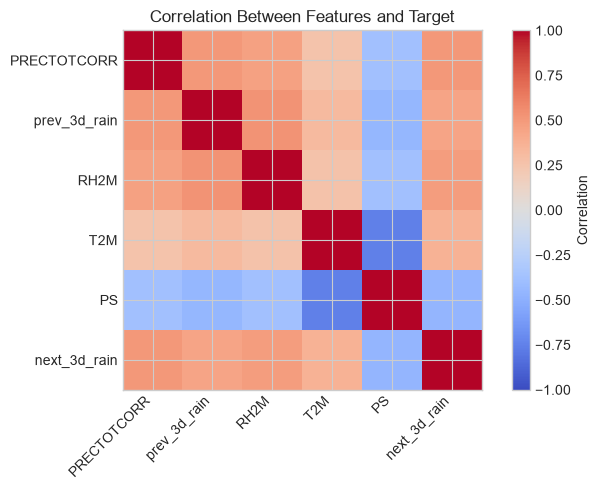

In [7]:
correlation_columns = features + ["next_3d_rain"]
correlation_table = data[correlation_columns].corr()[["next_3d_rain"]].sort_values(
    "next_3d_rain", ascending=False
)
display(correlation_table)

plt.figure(figsize=(7, 5))
corr_matrix = data[correlation_columns].corr()
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45, ha="right")
plt.yticks(range(len(corr_matrix.index)), corr_matrix.index)
plt.title("Correlation Between Features and Target")
plt.tight_layout()
plt.show()

### Graph 4: Monthly Average Rainfall Pattern

This graph helps explain seasonality. Kathmandu rainfall is usually higher during the monsoon months.

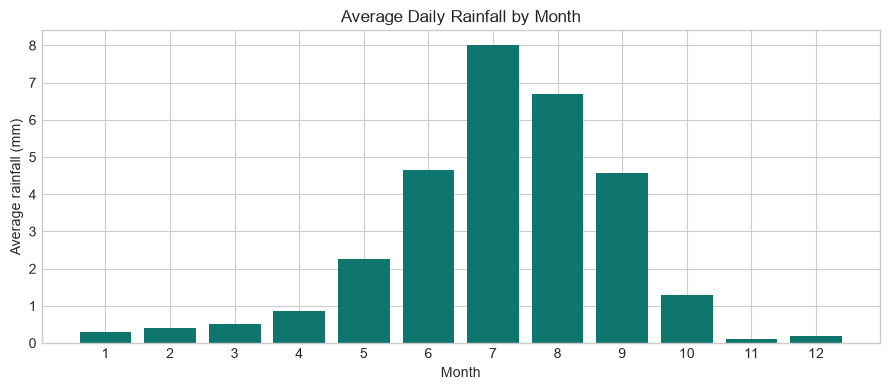

In [8]:
monthly_rain = df.assign(MONTH=df["DATE"].dt.month).groupby("MONTH")["PRECTOTCORR"].mean()

plt.figure(figsize=(9, 4))
plt.bar(monthly_rain.index, monthly_rain.values, color="#0f766e")
plt.title("Average Daily Rainfall by Month")
plt.xlabel("Month")
plt.ylabel("Average rainfall (mm)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

## Module 4: Risk Classification

The regression model predicts rainfall in millimeters. These rules convert predicted rainfall into a simple risk category for presentation.

In [9]:
def get_risk(predicted_rain):
    if predicted_rain < 8:
        return "LOW"
    elif predicted_rain < 22.7:
        return "MODERATE"
    else:
        return "HIGH"


def get_risk_message(risk_level):
    messages = {
        "LOW": "Low rainfall risk.",
        "MODERATE": "Moderate rainfall expected. Stay aware.",
        "HIGH": "Heavy rainfall may occur. Stay alert for local flood and river warnings.",
    }
    return messages[risk_level]


for value in [3, 12, 30]:
    level = get_risk(value)
    print(f"{value} mm -> {level}: {get_risk_message(level)}")

3 mm -> LOW: Low rainfall risk.
12 mm -> MODERATE: Moderate rainfall expected. Stay aware.
30 mm -> HIGH: Heavy rainfall may occur. Stay alert for local flood and river warnings.


### Graph 5: Previous 3-Day Rain vs Next 3-Day Rain

This scatter plot compares recent rainfall with future rainfall. The relationship is not perfect, which is why the model has errors, but recent rain can still provide useful information.

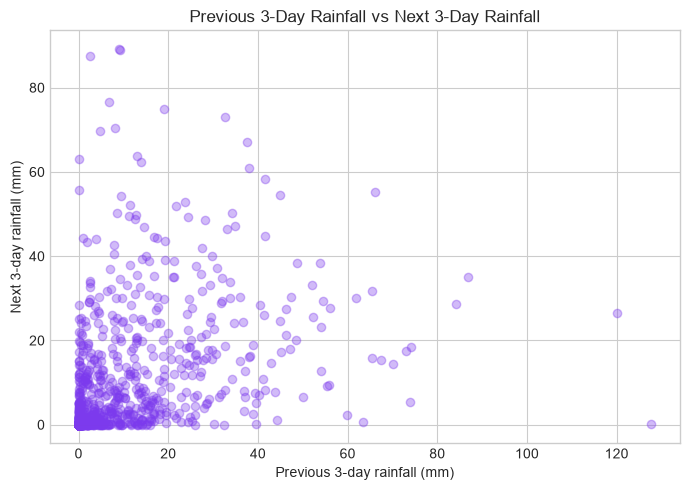

In [10]:
sample = data.sample(n=min(1200, len(data)), random_state=42)

plt.figure(figsize=(7, 5))
plt.scatter(sample["prev_3d_rain"], sample["next_3d_rain"], alpha=0.35, color="#7c3aed")
plt.title("Previous 3-Day Rainfall vs Next 3-Day Rainfall")
plt.xlabel("Previous 3-day rainfall (mm)")
plt.ylabel("Next 3-day rainfall (mm)")
plt.tight_layout()
plt.show()

## Module 5: Train Linear Regression

The split is chronological: older data is used for training and newer data is used for testing. This avoids randomly mixing future records into the training set.

In [11]:
def find_split_index(data, selected_date=None, train_ratio=0.8):
    split_index = int(len(data) * train_ratio)

    if selected_date is None:
        return split_index

    selected_date = pd.to_datetime(selected_date)
    matching_rows = data.index[data["DATE"] == selected_date].tolist()

    if not matching_rows:
        raise ValueError(f"Selected date {selected_date.date()} was not found in the data.")

    selected_index = matching_rows[0]

    # Keep the demo date in testing if the normal 80/20 split would train on it.
    if selected_index < split_index:
        split_index = selected_index

    if split_index <= 0 or split_index >= len(data):
        raise ValueError("Cannot create a valid chronological train/test split.")

    return split_index


def train_model(data, features, selected_date=None):
    split_index = find_split_index(data, selected_date)

    train_data = data.iloc[:split_index].copy()
    test_data = data.iloc[split_index:].copy()

    X_train = train_data[features]
    y_train = train_data["next_3d_rain"]
    X_test = test_data[features]
    y_test = test_data["next_3d_rain"]

    model = LinearRegression()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    return model, train_data, test_data, y_test, y_pred, mae, r2


model, train_data, test_data, y_test, y_pred, mae, r2 = train_model(data, features, selected_date)

print(f"Training rows: {len(train_data)}")
print(f"Testing rows: {len(test_data)}")
print(f"Train date range: {train_data['DATE'].min().date()} to {train_data['DATE'].max().date()}")
print(f"Test date range: {test_data['DATE'].min().date()} to {test_data['DATE'].max().date()}")
print(f"Demo date in training data: {(train_data['DATE'] == pd.Timestamp(selected_date)).any()}")
print(f"Demo date in testing data: {(test_data['DATE'] == pd.Timestamp(selected_date)).any()}")
print(f"MAE: {mae:.2f} mm")
print(f"R2: {r2:.2f}")

Training rows: 12267
Testing rows: 3067
Train date range: 1982-01-04 to 2015-08-05
Test date range: 2015-08-06 to 2023-12-28
Demo date in training data: False
Demo date in testing data: True
MAE: 7.34 mm
R2: 0.39


### Graph 6: What Linear Regression Learned

These coefficients are learned from the training data. They show how each input contributes to the rainfall prediction while the other inputs are held constant.

Model intercept: 451.3561


,Feature,Coefficient
4,PS,-5.237529
0,PRECTOTCORR,0.645601
3,T2M,0.186461
2,RH2M,0.126358
1,prev_3d_rain,0.087650


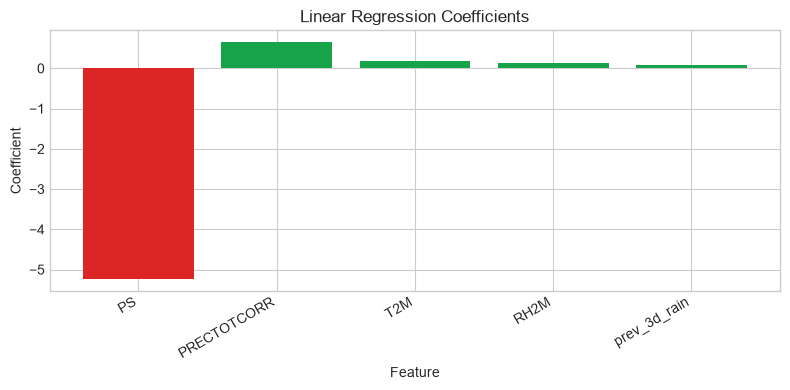

In [12]:
coefficient_table = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_,
}).sort_values("Coefficient", key=lambda s: s.abs(), ascending=False)

print(f"Model intercept: {model.intercept_:.4f}")
display(coefficient_table)

plt.figure(figsize=(8, 4))
colors = ["#16a34a" if value >= 0 else "#dc2626" for value in coefficient_table["Coefficient"]]
plt.bar(coefficient_table["Feature"], coefficient_table["Coefficient"], color=colors)
plt.title("Linear Regression Coefficients")
plt.xlabel("Feature")
plt.ylabel("Coefficient")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Graph 7: Actual vs Predicted Rainfall

Each point compares the model prediction against the real next-3-day rainfall. Points closer to the diagonal line are more accurate.

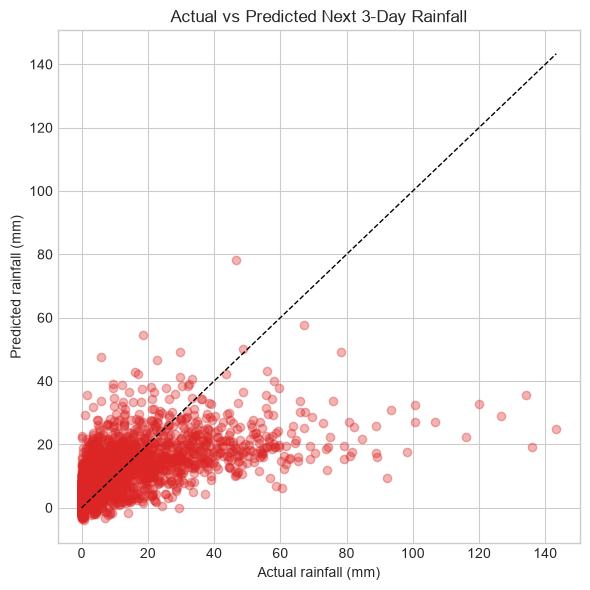

In [13]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.35, color="#dc2626")
limit = max(float(y_test.max()), float(np.max(y_pred)))
plt.plot([0, limit], [0, limit], color="black", linestyle="--", linewidth=1)
plt.title("Actual vs Predicted Next 3-Day Rainfall")
plt.xlabel("Actual rainfall (mm)")
plt.ylabel("Predicted rainfall (mm)")
plt.tight_layout()
plt.show()

### Graph 8: Prediction Error Distribution

The model is not perfect. This graph shows the prediction errors on the test set. Smaller errors near zero mean better predictions.

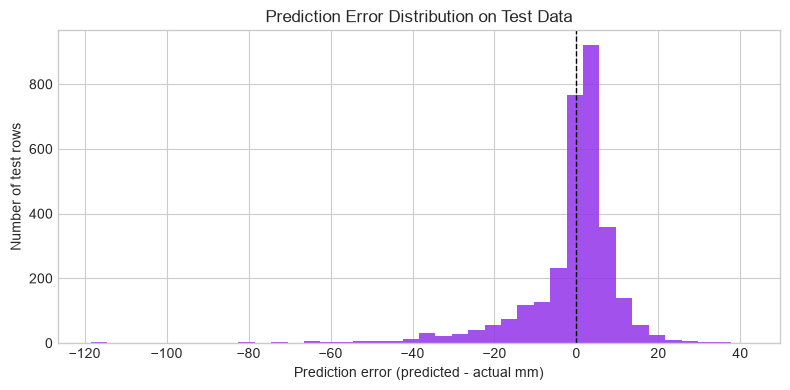

,Metric,Value
0,Mean error,-1.11 mm
1,Mean absolute error,7.34 mm
2,Median absolute error,4.13 mm
3,Largest over-prediction,41.66 mm
4,Largest under-prediction,-118.52 mm


In [14]:
prediction_errors = y_pred - y_test

plt.figure(figsize=(8, 4))
plt.hist(prediction_errors, bins=40, color="#9333ea", alpha=0.85)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Prediction Error Distribution on Test Data")
plt.xlabel("Prediction error (predicted - actual mm)")
plt.ylabel("Number of test rows")
plt.tight_layout()
plt.show()

error_summary = pd.DataFrame({
    "Metric": ["Mean error", "Mean absolute error", "Median absolute error", "Largest over-prediction", "Largest under-prediction"],
    "Value": [
        f"{prediction_errors.mean():.2f} mm",
        f"{np.mean(np.abs(prediction_errors)):.2f} mm",
        f"{np.median(np.abs(prediction_errors)):.2f} mm",
        f"{prediction_errors.max():.2f} mm",
        f"{prediction_errors.min():.2f} mm",
    ],
})
display(error_summary)

## Module 6: Demo Prediction for 3 July 2020

This section treats `2020-07-03` as today. The model only uses the weather values available on that date, then predicts rainfall for the next 3 days.

In [15]:
def predict_date(model, data, features, selected_date, test_data=None):
    selected_date = pd.to_datetime(selected_date)

    if test_data is not None and selected_date not in set(test_data["DATE"]):
        raise ValueError(f"{selected_date.date()} is not inside the test set.")

    selected_rows = data[data["DATE"] == selected_date]
    if selected_rows.empty:
        raise ValueError(f"Selected date {selected_date.date()} was not found in the data.")

    row = selected_rows.iloc[0]

    X_demo = row[features].to_frame().T
    predicted_rain = float(model.predict(X_demo)[0])

    actual_rain = float(row["next_3d_rain"])
    risk_level = get_risk(predicted_rain)

    return {
        "selected_date": row["DATE"].date(),
        "today_rainfall": float(row["PRECTOTCORR"]),
        "previous_3d_rainfall": float(row["prev_3d_rain"]),
        "humidity": float(row["RH2M"]),
        "temperature": float(row["T2M"]),
        "pressure": float(row["PS"]),
        "prediction_start": (row["DATE"] + pd.Timedelta(days=1)).date(),
        "prediction_end": (row["DATE"] + pd.Timedelta(days=3)).date(),
        "predicted_next_3d_rainfall": predicted_rain,
        "actual_next_3d_rainfall": actual_rain,
        "risk_level": risk_level,
        "risk_message": get_risk_message(risk_level),
    }


result = predict_date(model, data, features, selected_date, test_data)

print("Demo Prediction")
print("---------------")
print(f"Selected Date: {result['selected_date']}")
print(f"Today's Rainfall: {result['today_rainfall']:.2f} mm")
print(f"Previous 3-Day Rainfall: {result['previous_3d_rainfall']:.2f} mm")
print(f"Humidity: {result['humidity']:.2f} %")
print(f"Temperature: {result['temperature']:.2f} C")
print(f"Pressure: {result['pressure']:.2f} kPa")
print(f"Prediction period: {result['prediction_start']} to {result['prediction_end']}")
print(f"Predicted Next 3-Day Rainfall: {result['predicted_next_3d_rainfall']:.2f} mm")
print(f"Actual Next 3-Day Rainfall: {result['actual_next_3d_rainfall']:.2f} mm")
print(f"Rainfall-Based Flood Risk: {result['risk_level']}")
print(result["risk_message"])

Demo Prediction
---------------
Selected Date: 2020-07-03
Today's Rainfall: 26.19 mm
Previous 3-Day Rainfall: 13.33 mm
Humidity: 90.44 %
Temperature: 22.48 C
Pressure: 86.80 kPa
Prediction period: 2020-07-04 to 2020-07-06
Predicted Next 3-Day Rainfall: 30.43 mm
Actual Next 3-Day Rainfall: 31.84 mm
Rainfall-Based Flood Risk: HIGH
Heavy rainfall may occur. Stay alert for local flood and river warnings.


### Graph 9: Demo Prediction Compared With Actual Rainfall

For the selected date, the prediction is close to the real 3-day rainfall total. This supports the risk result for this example.

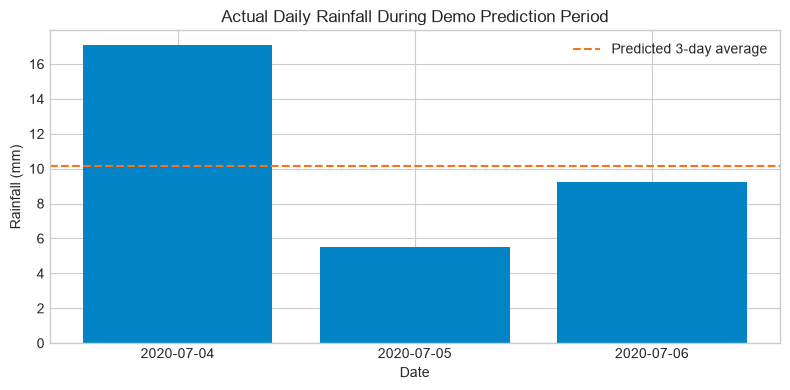

,Metric,Rainfall_mm
0,Predicted 3-day total,30.434693
1,Actual 3-day total,31.840000


In [16]:
demo_dates = pd.date_range(result["prediction_start"], result["prediction_end"])
demo_actual_daily = df[df["DATE"].isin(demo_dates)][["DATE", "PRECTOTCORR"]].copy()

plt.figure(figsize=(8, 4))
plt.bar(demo_actual_daily["DATE"].dt.strftime("%Y-%m-%d"), demo_actual_daily["PRECTOTCORR"], color="#0284c7")
plt.axhline(
    result["predicted_next_3d_rainfall"] / 3,
    color="#f97316",
    linestyle="--",
    label="Predicted 3-day average",
)
plt.title("Actual Daily Rainfall During Demo Prediction Period")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")
plt.legend()
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({
    "Metric": ["Predicted 3-day total", "Actual 3-day total"],
    "Rainfall_mm": [
        result["predicted_next_3d_rainfall"],
        result["actual_next_3d_rainfall"],
    ],
})
display(comparison)

## Module 7: Presentation Summary

This notebook now performs real analysis using the actual `Kathmandu_Daily_Climate_Data.csv` file. It checks the data, creates features, trains a real Linear Regression model, evaluates the test-set accuracy, and runs the July 2020 demo prediction.

Key points to say in the presentation:

- The CSV has daily Kathmandu weather records from 1982 to 2023.
- The model predicts rainfall, not confirmed flood events.
- It avoids data leakage by using past and present weather as input features.
- It uses a chronological train/test split, which is better for historical time-based data.
- Linear Regression learns coefficients for each weather feature.
- The predicted rainfall is converted into a LOW, MODERATE, or HIGH risk indicator.

In [17]:
summary = pd.DataFrame({
    "Item": [
        "Model",
        "Training rows",
        "Testing rows",
        "MAE",
        "R2",
        "Selected date",
        "Predicted next 3-day rainfall",
        "Actual next 3-day rainfall",
        "Risk level",
    ],
    "Value": [
        "LinearRegression",
        len(train_data),
        len(test_data),
        f"{mae:.2f} mm",
        f"{r2:.2f}",
        str(result["selected_date"]),
        f"{result['predicted_next_3d_rainfall']:.2f} mm",
        f"{result['actual_next_3d_rainfall']:.2f} mm",
        result["risk_level"],
    ],
})

display(summary)

,Item,Value
0,Model,LinearRegression
1,Training rows,12267
2,Testing rows,3067
3,MAE,7.34 mm
4,R2,0.39
5,Selected date,2020-07-03
6,Predicted next 3-day rainfall,30.43 mm
7,Actual next 3-day rainfall,31.84 mm
8,Risk level,HIGH
